## 1. Load the Dataset

In [1]:
import json
import os

# Load the dataset
dataset_path = os.path.join(os.getcwd(), 'text_segmentation_dataset.json')
with open(dataset_path, 'r') as f:
    dataset = json.load(f)

metadata = dataset['metadata']
word_counts = dataset['word_counts']
test_cases = dataset['test_cases']

print(f"Vocabulary size : {metadata['vocabulary_size']}")
print(f"Test case count : {metadata['test_case_count']}")
print(f"Total corpus words: {metadata['total_corpus_words']}")
print(f"\nSample vocabulary entries (first 10):")
for i, (word, count) in enumerate(list(word_counts.items())[:10]):
    print(f"  {word:>12s} -> {count}")

Vocabulary size : 1500
Test case count : 1000
Total corpus words: 735040

Sample vocabulary entries (first 10):
           the -> 69971
            of -> 36412
           and -> 28853
            to -> 26158
             a -> 23195
            in -> 21337
          that -> 10594
            is -> 10109
           was -> 9815
            he -> 9548


## 2. Build the Vocabulary

In [2]:
# Build the vocabulary set and find the maximum word length
vocabulary = set(word_counts.keys())
max_word_len = max(len(w) for w in vocabulary)

print(f"Number of words in vocabulary: {len(vocabulary)}")
print(f"Maximum word length           : {max_word_len}")
print(f"\nSome long words in vocabulary:")
long_words = sorted([w for w in vocabulary if len(w) >= 12], key=len, reverse=True)[:10]
for w in long_words:
    print(f"  {w} (len={len(w)})")

Number of words in vocabulary: 1500
Maximum word length           : 14

Some long words in vocabulary:
  responsibility (len=14)
  administration (len=14)
  circumstances (len=13)
  international (len=13)
  understanding (len=13)
  approximately (len=13)
  requirements (len=12)
  professional (len=12)
  nevertheless (len=12)
  construction (len=12)


## 3. Greedy Segmentation (Longest Match First)

In [3]:
def greedy_segment(text, vocabulary, max_word_len):
    """
    Segment `text` using a greedy longest-match-first strategy.
    
    Algorithm:
      1. Start at position i = 0.
      2. Try lengths from max_word_len down to 1.
      3. If text[i:i+length] is in the vocabulary, accept it as a word,
         advance i by `length`, and repeat.
      4. If no match is found for any length, take the single character
         text[i] as an unknown token and advance i by 1.
    
    Returns:
      A string of space-separated words.
    """
    words = []
    i = 0
    n = len(text)
    
    while i < n:
        matched = False
        # Try longest possible match first
        for length in range(min(max_word_len, n - i), 0, -1):
            candidate = text[i:i + length]
            if candidate in vocabulary:
                words.append(candidate)
                i += length
                matched = True
                break
        
        if not matched:
            # No word found — consume a single character
            words.append(text[i])
            i += 1
    
    return ' '.join(words)

# Quick test
sample = test_cases[0]
pred = greedy_segment(sample['input'], vocabulary, max_word_len)
print(f"Input       : {sample['input']}")
print(f"Ground Truth: {sample['ground_truth']}")
print(f"Prediction  : {pred}")

Input       : itthatthecitytakestepstothisproblem
Ground Truth: it that the city take steps to this problem
Prediction  : it that the city takes t e p s to this problem


In [4]:
def word_edit_distance(pred_words, true_words):
    """
    Compute the Levenshtein edit distance between two lists of words.
    Operations: insert, delete, substitute (each costs 1).
    """
    m, n = len(pred_words), len(true_words)
    # dp[i][j] = edit distance between pred_words[:i] and true_words[:j]
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    
    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j
    
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if pred_words[i - 1] == true_words[j - 1]:
                dp[i][j] = dp[i - 1][j - 1]
            else:
                dp[i][j] = 1 + min(
                    dp[i - 1][j],      # deletion
                    dp[i][j - 1],      # insertion
                    dp[i - 1][j - 1]   # substitution
                )
    
    return dp[m][n]

## 5. Run Greedy Segmentation on All Test Cases

In [5]:
exact_matches = 0
total_edit_distance = 0
results = []

for idx, tc in enumerate(test_cases):
    input_text = tc['input']
    ground_truth = tc['ground_truth']
    
    prediction = greedy_segment(input_text, vocabulary, max_word_len)
    
    pred_words = prediction.split()
    true_words = ground_truth.split()
    
    is_correct = (prediction == ground_truth)
    ed = word_edit_distance(pred_words, true_words)
    
    exact_matches += int(is_correct)
    total_edit_distance += ed
    
    results.append({
        'index': idx,
        'input': input_text,
        'ground_truth': ground_truth,
        'prediction': prediction,
        'correct': is_correct,
        'edit_distance': ed
    })

total = len(test_cases)
accuracy = exact_matches / total
avg_edit_distance = total_edit_distance / total

print("=" * 60)
print("   GREEDY (LONGEST MATCH) SEGMENTATION RESULTS")
print("=" * 60)
print(f"  Total test cases   : {total}")
print(f"  Exact matches      : {exact_matches}")
print(f"  Accuracy           : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"  Total edit distance: {total_edit_distance}")
print(f"  Avg edit distance  : {avg_edit_distance:.4f}")
print("=" * 60)

   GREEDY (LONGEST MATCH) SEGMENTATION RESULTS
  Total test cases   : 1000
  Exact matches      : 691
  Accuracy           : 0.6910 (69.10%)
  Total edit distance: 1260
  Avg edit distance  : 1.2600


## 5.1 Segmented Output for All Test Cases

In [6]:
# Print segmented output for all test cases
print('=' * 80)
print('   SEGMENTED OUTPUT — GREEDY (LONGEST MATCH) — ALL TEST CASES')
print('=' * 80)
for r in results:
    status = 'CORRECT' if r['correct'] else 'WRONG'
    print(f"\n[{status}] Test Case {r['index'] + 1}")
    print(f"  Input       : {r['input']}")
    print(f"  Ground Truth: {r['ground_truth']}")
    print(f"  Prediction  : {r['prediction']}")
    if not r['correct']:
        print(f"  Edit Dist.  : {r['edit_distance']}")
print('\n' + '=' * 80)
correct_count = sum(1 for r in results if r['correct'])
incorrect_count = sum(1 for r in results if not r['correct'])
print(f'Total: {len(results)} test cases | Correct: {correct_count} | Incorrect: {incorrect_count}')
print('=' * 80)


   SEGMENTED OUTPUT — GREEDY (LONGEST MATCH) — ALL TEST CASES

[WRONG] Test Case 1
  Input       : itthatthecitytakestepstothisproblem
  Ground Truth: it that the city take steps to this problem
  Prediction  : it that the city takes t e p s to this problem
  Edit Dist.  : 5

[CORRECT] Test Case 2
  Input       : oftitlelawwasalsobythe
  Ground Truth: of title law was also by the
  Prediction  : of title law was also by the

[WRONG] Test Case 3
  Input       : failuretodothiswillcontinuetoplaceaon
  Ground Truth: failure to do this will continue to place a on
  Prediction  : failure to do this will continue top l a c e a on
  Edit Dist.  : 5

[CORRECT] Test Case 4
  Input       : onotherthethat
  Ground Truth: on other the that
  Prediction  : on other the that

[CORRECT] Test Case 5
  Input       : williamforfromhiswifeincourt
  Ground Truth: william for from his wife in court
  Prediction  : william for from his wife in court

[CORRECT] Test Case 6
  Input       : thecouplewasmarried

## 6. Detailed Analysis

In [7]:
# Show some correctly segmented examples
correct_examples = [r for r in results if r['correct']]
print(f"\n--- Correctly Segmented Examples (showing up to 5) ---\n")
for r in correct_examples[:5]:
    print(f"  Input : {r['input']}")
    print(f"  Output: {r['prediction']}")
    print()


--- Correctly Segmented Examples (showing up to 5) ---

  Input : oftitlelawwasalsobythe
  Output: of title law was also by the

  Input : onotherthethat
  Output: on other the that

  Input : williamforfromhiswifeincourt
  Output: william for from his wife in court

  Input : thecouplewasmarried
  Output: the couple was married

  Input : thetheasandhisageas
  Output: the the as and his age as



In [8]:
# Show some incorrectly segmented examples
incorrect_examples = [r for r in results if not r['correct']]
print(f"\n--- Incorrectly Segmented Examples (showing up to 10) ---\n")
for r in incorrect_examples[:10]:
    print(f"  Input       : {r['input']}")
    print(f"  Ground Truth: {r['ground_truth']}")
    print(f"  Prediction  : {r['prediction']}")
    print(f"  Edit Distance: {r['edit_distance']}")
    print()


--- Incorrectly Segmented Examples (showing up to 10) ---

  Input       : itthatthecitytakestepstothisproblem
  Ground Truth: it that the city take steps to this problem
  Prediction  : it that the city takes t e p s to this problem
  Edit Distance: 5

  Input       : failuretodothiswillcontinuetoplaceaon
  Ground Truth: failure to do this will continue to place a on
  Prediction  : failure to do this will continue top l a c e a on
  Edit Distance: 5

  Input       : theyhaveasonwilliamandadaughterof
  Ground Truth: they have a son william and a daughter of
  Prediction  : they have as on william and a daughter of
  Edit Distance: 2

  Input       : forthesaidthatanpropertyhasbeenagreedupon
  Ground Truth: for the said that an property has been agreed upon
  Prediction  : forth e said that an property has been agreed upon
  Edit Distance: 2

  Input       : samstatedepartmentpublicrelationsdirectortoworkforcampaign
  Ground Truth: sam state department public relations director to wor

In [9]:
# Distribution of edit distances
from collections import Counter

ed_dist = Counter(r['edit_distance'] for r in results)
print("\n--- Edit Distance Distribution ---\n")
print(f"  {'Edit Distance':<15} {'Count':<10} {'Percentage':<10}")
print(f"  {'-'*35}")
for ed_val in sorted(ed_dist.keys()):
    count = ed_dist[ed_val]
    pct = count / total * 100
    print(f"  {ed_val:<15} {count:<10} {pct:.1f}%")


--- Edit Distance Distribution ---

  Edit Distance   Count      Percentage
  -----------------------------------
  0               691        69.1%
  2               91         9.1%
  3               63         6.3%
  4               51         5.1%
  5               28         2.8%
  6               38         3.8%
  7               19         1.9%
  8               5          0.5%
  9               5          0.5%
  10              3          0.3%
  11              4          0.4%
  12              1          0.1%
  13              1          0.1%


## 7. Visualization

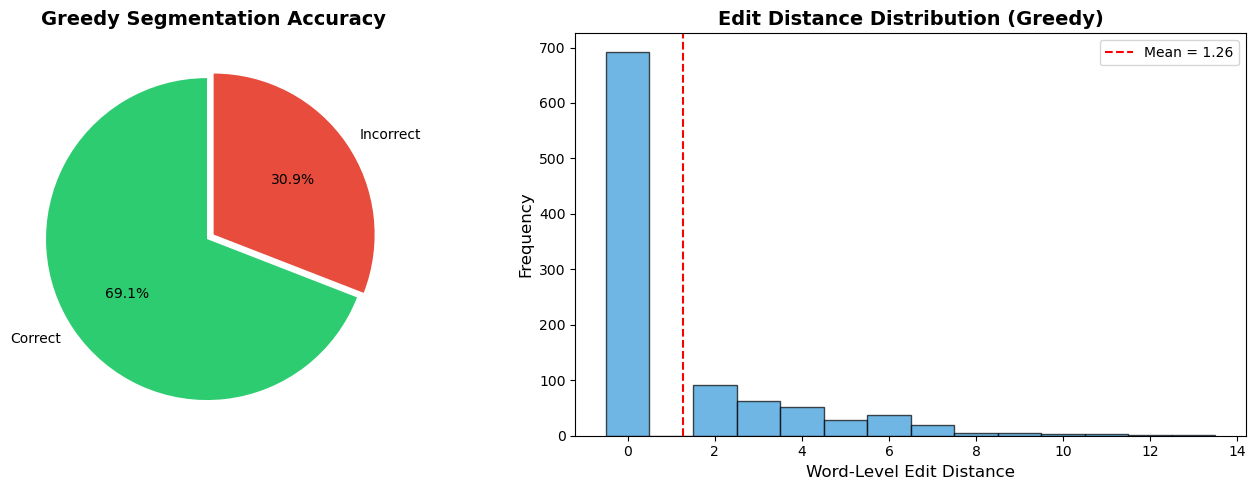

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Accuracy pie chart
axes[0].pie(
    [exact_matches, total - exact_matches],
    labels=['Correct', 'Incorrect'],
    autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c'],
    startangle=90,
    explode=(0.05, 0)
)
axes[0].set_title('Greedy Segmentation Accuracy', fontsize=14, fontweight='bold')

# Plot 2: Edit distance histogram
edit_distances = [r['edit_distance'] for r in results]
axes[1].hist(edit_distances, bins=range(0, max(edit_distances) + 2),
             color='#3498db', edgecolor='black', alpha=0.7, align='left')
axes[1].set_xlabel('Word-Level Edit Distance', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Edit Distance Distribution (Greedy)', fontsize=14, fontweight='bold')
axes[1].axvline(x=avg_edit_distance, color='red', linestyle='--', label=f'Mean = {avg_edit_distance:.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()